# 1.5 The SEIR Model & Wrap-Up

Look back at the real-world Wuhan COVID-19 equations from [**1.1 Introduction**](01-intro-to-modelling.md)—almost every modern pandemic model includes an **Exposed ($E$)** compartment representing people who have been infected but are still in the **incubation period** (not yet infectious).

Our four compartments are now:

- **$S$ (`u[1]`)** — **Susceptible** population
- **$E$ (`u[2]`)** — **Exposed** population (infected, incubating, not yet infectious)
- **$I$ (`u[3]`)** — **Infectious** population
- **$R$ (`u[4]`)** — **Recovered** population

## SEIR Diagram & Equations

![SEIR compartmental model](../images/seir-diagram.svg)

Adding the incubation rate $\sigma$ (so the average incubation period is $1/\sigma$ days) alongside births ($\lambda$), natural deaths ($\mu$), and waning immunity ($\epsilon$) yields four coupled ODEs:

$$
\begin{aligned}
\frac{dS}{dt} &= \lambda - r \beta S I - \mu S + \epsilon R \\
\frac{dE}{dt} &= r \beta S I - \sigma E - \mu E \\
\frac{dI}{dt} &= \sigma E - \gamma I - \mu I \\
\frac{dR}{dt} &= \gamma I - \mu R - \epsilon R
\end{aligned}
$$

Notice how **only Infectious ($I$) individuals** transmit the infection to Susceptibles ($S$), moving them into Exposed ($E$)!

## Step 1: Load Julia Packages

In [ ]:
using DifferentialEquations
using Plots
println("Ready for SEIR simulation!")

Ready for SEIR simulation!

## Step 2: Run the Baseline SEIR Simulation

Run the cell below to simulate all four compartments over 200 days. Watch how the yellow **Exposed** wave peaks slightly *before* the orange **Infectious** wave—reflecting the $1/\sigma = 5$-day incubation delay!

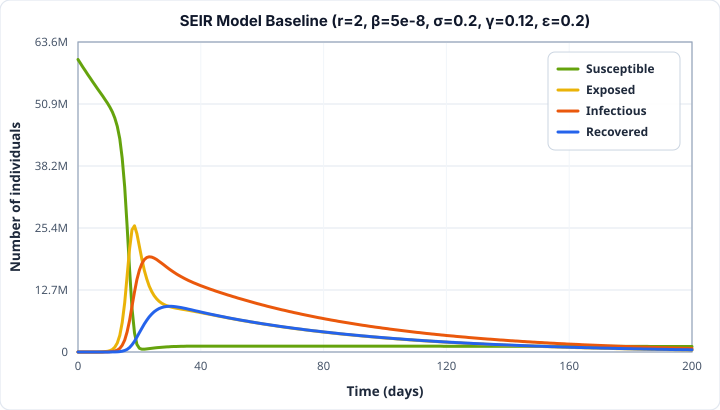

In [ ]:
# Define parameters
r       = 2        # Number of contacts per unit time
beta    = 5e-8     # Probability of disease transmission
sigma   = 0.2      # Incubation rate (1/5 days -> Exposed to Infectious)
gamma   = 0.12     # Recovery rate (try 0.07)
lambda  = 10000.0  # Birth and immigration inflow
mu      = 1 / 60   # Natural death and emigration rate
epsilon = 1 / 5    # Loss of immunity rate (Recovered to Susceptible)
N       = 6e7      # Population size

# Define differential equations
function SEIR!(du, u, p, t)
    r, beta, sigma, gamma, lambda, mu, epsilon = p
    du[1] = lambda - r * beta * u[1] * u[3] - mu * u[1] + epsilon * u[4]  # dS/dt
    du[2] =          r * beta * u[1] * u[3] - sigma * u[2] - mu * u[2]    # dE/dt
    du[3] =                                   sigma * u[2] - gamma * u[3] - mu * u[3]   # dI/dt
    du[4] =                                                  gamma * u[3] - mu * u[4] - epsilon * u[4]  # dR/dt
end

# Initial conditions, parameters, and time span
u0    = [N - 20.0, 10.0, 10.0, 0.0]
p     = [r, beta, sigma, gamma, lambda, mu, epsilon]
tspan = (0.0, 200.0)

# Solve ODE & plot
prob = ODEProblem(SEIR!, u0, tspan, p)
sol  = solve(prob)

plot(sol, lw=3, label=["Susceptible" "Exposed" "Infectious" "Recovered"],
     xlabel="Time (days)", ylabel="Number of individuals",
     title="SEIR Model Baseline",
     xtickfontsize=10, ytickfontsize=10, xguidefontsize=14, yguidefontsize=14, legendfontsize=10)

## Challenge: What If Infected People Have a Different Death Rate?

Right now, every compartment ($S$, $E$, $I$, and $R$) has the exact same death rate `mu`. In a serious outbreak, however, **infectious individuals ($I$) experience additional disease-induced mortality**!

**Your task:** Modify the starter SEIR code below so that **Infectious (`u[3]`)** people have their own higher death rate (e.g. `mu_I = 0.08`, compared to `mu = 1/60`).
Run your modified model and observe how increased mortality among infectious people affects **total population survival** and the **spread of the epidemic**!

In [ ]:
# Challenge starter code — modify SEIR_mortality! so Infectious (u[3]) has its own death rate!
r       = 2
beta    = 5e-8
sigma   = 0.2
gamma   = 0.12
lambda  = 10000.0
mu      = 1 / 60
epsilon = 1 / 5
N       = 6e7

function SEIR_mortality!(du, u, p, t)
    r, beta, sigma, gamma, lambda, mu, epsilon = p
    du[1] = lambda - r * beta * u[1] * u[3] - mu * u[1] + epsilon * u[4]
    du[2] =          r * beta * u[1] * u[3] - sigma * u[2] - mu * u[2]
    du[3] =                                   sigma * u[2] - gamma * u[3] - mu * u[3]
    du[4] =                                                  gamma * u[3] - mu * u[4] - epsilon * u[4]
end

u0    = [N - 20.0, 10.0, 10.0, 0.0]
p     = [r, beta, sigma, gamma, lambda, mu, epsilon]
tspan = (0.0, 200.0)

prob = ODEProblem(SEIR_mortality!, u0, tspan, p)
sol  = solve(prob)

plot(sol, lw=3, label=["Susceptible" "Exposed" "Infectious" "Recovered"],
     xlabel="Time (days)", ylabel="Number of individuals",
     title="SEIR Challenge: Disease-Induced Mortality",
     xtickfontsize=10, ytickfontsize=10, xguidefontsize=14, yguidefontsize=14, legendfontsize=10)

````{admonition} Hint — Disease-Induced Mortality
:class: tip, dropdown

1. Add a new parameter `mu_I = 0.08` (death rate for infectious individuals) and include it in `p = [r, beta, sigma, gamma, lambda, mu, mu_I, epsilon]`.
2. Unpack `mu_I` inside `SEIR_mortality!`:
   `r, beta, sigma, gamma, lambda, mu, mu_I, epsilon = p`
3. Replace `- mu * u[3]` in the `du[3]` equation with `- mu_I * u[3]`!
*(Bonus: try printing `sum(sol[:, end])` to compare how many people survive at day 200!)*
````

````{admonition} Reveal Solution — Disease-Induced Mortality
:class: note, dropdown

When infectious people die at a higher rate (`mu_I = 0.08`), two competing effects happen:
1. Fewer people survive overall (total population declines faster).
2. Because infectious individuals leave the `I` compartment more quickly, **each infected person has less time to infect others**—a classic evolutionary trade-off in epidemiology (extremely lethal pathogens can burn out faster unless they spread before causing severe illness!).

```julia
r       = 2
beta    = 5e-8
sigma   = 0.2
gamma   = 0.12
lambda  = 10000.0
mu      = 1 / 60    # Baseline death rate for S, E, R
mu_I    = 0.08      # Higher death rate for Infectious (I) individuals
epsilon = 1 / 5
N       = 6e7

function SEIR_mortality!(du, u, p, t)
    r, beta, sigma, gamma, lambda, mu, mu_I, epsilon = p
    du[1] = lambda - r * beta * u[1] * u[3] - mu * u[1] + epsilon * u[4]
    du[2] =          r * beta * u[1] * u[3] - sigma * u[2] - mu * u[2]
    du[3] =                                   sigma * u[2] - gamma * u[3] - mu_I * u[3]
    du[4] =                                                  gamma * u[3] - mu * u[4] - epsilon * u[4]
end

u0    = [N - 20.0, 10.0, 10.0, 0.0]
p     = [r, beta, sigma, gamma, lambda, mu, mu_I, epsilon]
tspan = (0.0, 200.0)

prob = ODEProblem(SEIR_mortality!, u0, tspan, p)
sol  = solve(prob)

println("Surviving population at day 200: ", round(Int, sum(sol[:, end])))

plot(sol, lw=3, label=["Susceptible" "Exposed" "Infectious" "Recovered"],
     xlabel="Time (days)", ylabel="Number of individuals",
     title="SEIR Solution (μ = $(round(mu, digits=3)), μ_I = $mu_I)",
     xtickfontsize=10, ytickfontsize=10, xguidefontsize=14, yguidefontsize=14, legendfontsize=10)
```
````

## Discussion & Looking Ahead

### Things You Might Ask of Population-Scale Models

These questions are great starting points for your **6-minute SSC assessment presentation**:

- **How does lowering the infection rate ($\beta$) affect the dynamics of a pandemic?** (e.g. masks, ventilation, treatments reducing viral load)
- **How does reducing contacts ($r$) affect the dynamics of a pandemic?** (e.g. lockdowns, school closures, remote work — and what happens if contacts are only reduced temporarily?)
- **How could you add vaccination to the SIR or SEIR model?** (Hint: move people directly from $S$ to $R$ at a vaccination rate $v$, or start with a fraction of $N$ already in $R$!)
- **What are the *limitations* of compartmental ODE models?** (Think about well-mixed populations, age groups, hospital capacity, superspreaders, and spatial geography!)

### Next Time in the SSC

- **Weeks 2–3:** Molecular Dynamics Modelling (zooming down to atoms & proteins!)
- **Weeks 4–5:** Cancer Signalling Modelling (and you can also explore our lab's [Interactive ODE Modelling Tutorials](https://mitchell.science/tutorials/) anytime!)